In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import geopandas as gpd
from shapely import wkt
from shapely.geometry import box
from shapely.geometry import Point
from shapely.ops import nearest_points
from scipy.spatial import cKDTree
from sklearn.impute import SimpleImputer

from scipy.interpolate import griddata
from scipy.spatial import distance
from scipy.spatial import cKDTree
from pyproj import CRS, Proj, Transformer
from shapely.geometry import box

from datetime import datetime, timedelta

import xarray as xr
import os
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

# Utils

In [4]:
def read_aod(filename):

    sds = gdal.Open(filename, gdal.GA_ReadOnly).GetSubDatasets()
    sds

    var = [var[0] for var in sds if 'Optical_Depth_055' in var[0]][0]
    blue_band_AOD = gdal.Open(var)

    data = blue_band_AOD.ReadAsArray()

    calibration_dict = blue_band_AOD.GetMetadata()

    proj = blue_band_AOD.GetProjection()

    geotransform = blue_band_AOD.GetGeoTransform()

    originX = geotransform[0]
    originY = geotransform[3]
    pixelWidth = geotransform[1]
    pixelHeight = geotransform[5]

    # Loop over orbits to apply the attributes

    """Given a MAIAC dataset and calibration parameters, return a masked
    array of calibrated data.

    Args:
        dataset (SDS): dataset in SDS format (e.g. blue band AOD).
        shape (List[int]): dataset shape as a list of [orbits, height, width].
        calibration_dict (Dict): dictionary containing, at a minimum,
            `valid_range` (list or tuple), `_FillValue` (int or float),
            `add_offset` (float), and `scale_factor` (float).

    Returns:
        corrected_AOD (np.ma.MaskedArray): masked array of calibrated data
            with a fill value of nan.
    """

    corrected_AOD = np.ma.empty(data.shape, dtype=np.double)
    
    if len(data.shape) == 2:
        data_orbit = data[:, :].astype(np.double)
        invalid_condition = (
                    (data_orbit < int(calibration_dict["valid_range"].split(',')[0])) |
                    (data_orbit > int(calibration_dict["valid_range"].split(',')[1])) |
                    (data_orbit == int(calibration_dict["_FillValue"]))
                )
        data_orbit[invalid_condition] = np.nan
        data_orbit = (
                    (data_orbit - int(calibration_dict["add_offset"])) *
                    float(calibration_dict["scale_factor"])
                )
        data_orbit = np.ma.masked_array(data_orbit, np.isnan(data_orbit))
        corrected_AOD[: :] = data_orbit
        corrected_AOD.fill_value = np.nan
    else:
        for orbit in range(data.shape[0]):
            data_orbit = data[orbit, :, :].astype(np.double)
            invalid_condition = (
                        (data_orbit < int(calibration_dict["valid_range"].split(',')[0])) |
                        (data_orbit > int(calibration_dict["valid_range"].split(',')[1])) |
                        (data_orbit == int(calibration_dict["_FillValue"]))
                    )
            data_orbit[invalid_condition] = np.nan
            data_orbit = (
                        (data_orbit - int(calibration_dict["add_offset"])) *
                        float(calibration_dict["scale_factor"])
                    )
            data_orbit = np.ma.masked_array(data_orbit, np.isnan(data_orbit))
            corrected_AOD[orbit, : :] = data_orbit
            corrected_AOD.fill_value = np.nan

    """Given an image shape, create a meshgrid of points
    between bounding coordinates.

    Args:
        alignment_dict (Dict): dictionary containing, at a minimum,
            `upper_left` (tuple), `lower_right` (tuple), `crs` (str),
            and `crs_params` (tuple).
        shape (List[int]): dataset shape as a list of
            [orbits, height, width].

    Returns:
        xv (np.array): x (longitude) coordinates.
        yv (np.array): y (latitude) coordinates.
    """

    # Determine grid bounds using two coordinates
    x0, y0 = originX, originY

    pixelWidth = geotransform[1]
    pixelHeight = geotransform[5]

    # Interpolate points between corners, inclusive of bounds
    if len(data.shape) == 2:
        x = np.linspace(x0, x0+pixelWidth*data.shape[1], data.shape[1], endpoint=True)
        y = np.linspace(y0, y0+pixelHeight*data.shape[0], data.shape[0], endpoint=True)
    else:
        x = np.linspace(x0, x0+pixelWidth*data.shape[2], data.shape[2], endpoint=True)
        y = np.linspace(y0, y0+pixelHeight*data.shape[1], data.shape[1], endpoint=True)

    # Return two 2D arrays representing X & Y coordinates of all points
    xv, yv = np.meshgrid(x, y)

    sinu_crs = Proj(proj).crs
    wgs84_crs = CRS.from_epsg("4326")

    """Transform points or arrays from one CRS to another CRS.

    Args:
        xv (np.array or float): x (longitude) coordinates or value.
        yv (np.array or float): y (latitude) coordinates or value.
        crs_from (CRS): source coordinate reference system.
        crs_to (CRS): destination coordinate reference system.

    Returns:
        lon, lat (tuple): x coordinate(s), y coordinate(s)
    """
    transformer = Transformer.from_crs(
        sinu_crs,
        wgs84_crs,
        always_xy=True,
    )
    lon, lat = transformer.transform(xv, yv)
  
    
    """
    Get the observation time
    """
    d = np.datetime64(calibration_dict['GRANULEBEGINNINGDATETIME'].split(',')[0].strip())
    date = str(d).partition('T')[0]

    if not 'T' in date: date = date+'T'

    obs_dt_list, corrected_AOD_grids_list = [], []
    
    if len(data.shape) == 2:
        i = 0
        time = calibration_dict['Orbit_time_stamp'].split()[i][-5:-3] + ':' + calibration_dict['Orbit_time_stamp'].split()[i][-3:-1]+':00'
        obs_time = np.datetime64(date + time)

        rounded_obs_time = pd.to_datetime(obs_time).round('60min').to_datetime64()
        obs_dt_list.append(rounded_obs_time)
    else:
        for i in range(data.shape[0]):

            time = calibration_dict['Orbit_time_stamp'].split()[i][-5:-3] + ':' + calibration_dict['Orbit_time_stamp'].split()[i][-3:-1]+':00'
            obs_time = np.datetime64(date + time)

            rounded_obs_time = pd.to_datetime(obs_time).round('60min').to_datetime64()
            obs_dt_list.append(rounded_obs_time)
        
    return corrected_AOD, lon, lat, obs_dt_list

In [ ]:
def calculate_extents(ds):
    min_lat = ds['lat'].values.min()
    max_lat = ds['lat'].values.max()
    min_lon = ds['lon'].values.min()
    max_lon = ds['lon'].values.max()
    return {'min_lat': min_lat, 'max_lat': max_lat, 'min_lon': min_lon, 'max_lon': max_lon}

extents_list = [calculate_extents(ds) for ds in datasets]

# Base grids - 1km

In [8]:
grid = pd.read_csv('grid_proj_1km.csv')[['x', 'y', 'geometry', 'lon', 'lat']]

grid['geometry'] = grid['geometry'].apply(wkt.loads)

grid_gdf = gpd.GeoDataFrame(grid, geometry='geometry', crs='ESRI:102003')

In [9]:
states = gpd.read_file('/us_boundaries/States/conus_states.shp')
five_states = states.loc[states['STUSPS'].isin(['NY','PA','OH','MD','WV'])]

polygon = box(-84, 37, -74, 43.5)
region = five_states.clip(polygon)
region_proj = region.to_crs('ESRI:102003')

res = 1000

min_x, min_y, max_x, max_y = region_proj.total_bounds

xnew = np.arange(min_x, max_x, res)
ynew = np.arange(min_y, max_y, res)

x_1km, y_1km = np.meshgrid(xnew,ynew)

transformer = Transformer.from_crs("ESRI:102003", "EPSG:4326", always_xy=True)

lon, lat = transformer.transform(x_1km, y_1km)

min_lon = lon.min()
max_lon = lon.max()
min_lat = lat.min()
max_lat = lat.max()

# Batch process MAIAC AOD into 1km grids

In [4]:
aod_path = '/MODIS MAIAC AOD/'   # aod path
pm_aod_path = '/PM_AOD/'

In [ ]:
for year in [str(y) for y in range(2004, 2024)]:
    files = [f for f in os.listdir(pm_aod_path) if f.startswith(year)]
    
    for f in tqdm(files):
        
        year, month, day = f[:4], f[5:7], f[8:10]
    
        if not os.path.exists(pm_aod_path+'MODIS_AOD_1km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv'):
        
            print(year, month, day)
            
            # ----------------------- add aod features
            doy = pd.to_datetime(datetime(int(year), int(month), int(day))).dayofyear
            
            if doy < 10:
                day_str = '00' + str(doy)
            elif doy < 100:
                day_str = '0' + str(doy)
            else:
                day_str = str(doy)
            
            date_doy = year + day_str
            
            filenames = [f for f in os.listdir(aod_path) if f.split('.')[1][1:] in date_doy]

            maiac_files_ = {}  
            
            for filename in filenames:

                tile_key = filename.split('.')[2]
                
                if tile_key not in maiac_files_:
                    maiac_files_[tile_key] = filename
            
            maiac_files = list(maiac_files_.values())
        
            if len(maiac_files) == 4:
            
                datasets = []
                
                for f in tqdm(maiac_files):
                
                     corrected_AOD, lon_2d, lat_2d, obs_dt_list = read_aod(aod_path + f)
                
                    aod_grids_list = []
                
                    for i in range(len(obs_dt_list)):
                
                        dt = obs_dt_list[i]
                
                        aod_ = corrected_AOD[i].data
                
                        aod_grids_list.append(aod_) 
    
                    if len(aod_grids_list) > 1 :
                    
                        aod_nanmean = np.nanmean(np.array(aod_grids_list), axis=0)
    
                    else:
    
                        aod_nanmean = corrected_AOD.data
                
                    ds = xr.Dataset(
                        data_vars=dict(
                            aod_grid=(["y", "x"], aod_nanmean),
                        ),
                        coords=dict(
                            lat=(["y", "x"], lat_2d),
                            lon=(["y", "x"], lon_2d),
                        )
                    )
                
                    datasets.append(ds)
                
                extents_and_datasets = list(zip(extents_list, datasets))
                
                extents_and_datasets.sort(key=lambda x: (-x[0]['min_lat'], x[0]['min_lon']))
                
                sorted_datasets = [x[1] for x in extents_and_datasets]
                
                lat_rows = sorted(set(x[0]['min_lat'] for x in extents_and_datasets), reverse=True)
                
                rows = []
                for lat in lat_rows:
                    row_datasets = [x[1] for x in extents_and_datasets if x[0]['min_lat'] == lat]
                    rows.append(row_datasets)
                
                merged_rows = [xr.concat(row, dim='x') for row in rows]
                ds_merged = xr.concat(merged_rows, dim='y')

                flat_lats = ds_merged['lat'].values.flatten()
                flat_lons = ds_merged['lon'].values.flatten()
                flat_aod = ds_merged['aod_grid'].values.flatten()
                
                mask = ~np.isnan(flat_aod)
                
                masked_lats = flat_lats[mask]
                masked_lons = flat_lons[mask]
                masked_aod = flat_aod[mask]
                
                lat_da = xr.DataArray(masked_lats, dims='points')
                lon_da = xr.DataArray(masked_lons, dims='points')
                aod_da = xr.DataArray(masked_aod, dims='points', coords={'lat': lat_da, 'lon': lon_da})
                
                tree = cKDTree(np.c_[masked_lats, masked_lons])
                
                query_points = np.c_[grid_gdf['lat'].values, grid_gdf['lon'].values]
                
                distances, indices = tree.query(query_points, k=1)
                
                selected_aod_values = np.full_like(grid_gdf['lat'].values, np.nan, dtype=np.float64)
                
                valid_mask = distances < 0.05
                
                valid_indices = indices[valid_mask]

                selected_aod_values[valid_mask] = masked_aod[valid_indices]
                
                grid_gdf['aod'] = selected_aod_values
            
                grid_gdf[['aod']].to_csv(pm_aod_path+'MODIS_AOD_1km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv', index=False)
        
            elif len(maiac_files) < 4 and len(maiac_files)>0:
        
                aod_list = []

                for f in tqdm(maiac_files):

                    corrected_AOD, lon_2d, lat_2d, obs_dt_list = read_aod(aod_path + f)
                
                    aod_grids_list = []
                
                    for i in range(len(obs_dt_list)):
                
                        dt = obs_dt_list[i]
                
                        aod_ = corrected_AOD[i].data
                
                        aod_grids_list.append(aod_) 
                
                    aod_nanmean = np.nanmean(np.array(aod_grids_list), axis=0)
                
                    ds = xr.Dataset(
                        data_vars=dict(
                            aod_grid=(["y", "x"], aod_nanmean),
                        ),
                        coords=dict(
                            lat=(["y", "x"], lat_2d),
                            lon=(["y", "x"], lon_2d),
                        )
                    )
                
                    flat_lats = ds['lat'].values.flatten()
                    flat_lons = ds['lon'].values.flatten()
                    flat_aod = ds['aod_grid'].values.flatten()
                    
                    mask = ~np.isnan(flat_aod)
                    
                    masked_lats = flat_lats[mask]
                    masked_lons = flat_lons[mask]
                    masked_aod = flat_aod[mask]
                    
                    lat_da = xr.DataArray(masked_lats, dims='points')
                    lon_da = xr.DataArray(masked_lons, dims='points')
                    aod_da = xr.DataArray(masked_aod, dims='points', coords={'lat': lat_da, 'lon': lon_da})
                    
                    tree = cKDTree(np.c_[masked_lats, masked_lons])
                    
                    query_points = np.c_[grid_gdf['lat'].values, grid_gdf['lon'].values]
                    
                    distances, indices = tree.query(query_points, k=1)
                    
                    selected_aod_values = np.full_like(grid_gdf['lat'].values, np.nan, dtype=np.float64)
                    
                    valid_mask = distances < 0.05
                    
                    valid_indices = indices[valid_mask]
                    
                    selected_aod_values[valid_mask] = masked_aod[valid_indices]
                    
                    aod_list.append(selected_aod_values)
                
                grid_gdf['aod'] =  np.nanmean(aod_list, axis=0)
                
                grid_gdf[['aod']].to_csv(pm_aod_path+'MODIS_AOD_1km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv', index=False)
            
            else:
                print('no modis files')

In [11]:
ds = xr.Dataset(
    {
        'aod': (('y', 'x'), pd.read_csv(pm_aod_path+'MODIS_AOD_1km_grid/MODIS_AOD_'+'2023'+'-'+'06'+'-'+'06'+'.csv')['aod'].values.reshape(x_1km.shape))
    },
    coords={
        'lat': (('y', 'x'), lat),
        'lon': (('y', 'x'), lon),
        'Projected Y': (('y', 'x'), y_1km),
        'Projected X': (('y', 'x'), x_1km),
    }
)

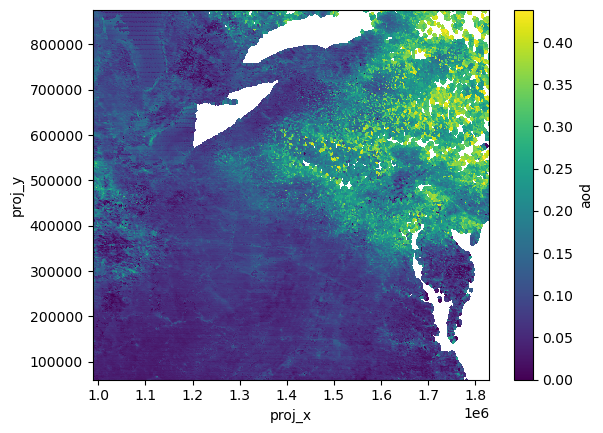

In [32]:
ds['aod'].plot()

# Base grids - 5km

In [122]:
grid = pd.read_csv('grid_proj_5km.csv')[['x', 'y', 'geometry', 'lon', 'lat']]

grid['geometry'] = grid['geometry'].apply(wkt.loads)

grid_gdf = gpd.GeoDataFrame(grid, geometry='geometry', crs='ESRI:102003')

In [123]:
states = gpd.read_file('F:/us_boundaries/States/conus_states.shp')
five_states = states.loc[states['STUSPS'].isin(['NY','PA','OH','MD','WV'])]

polygon = box(-84, 37, -74, 43.5)
region = five_states.clip(polygon)
region_proj = region.to_crs('ESRI:102003')

res = 5000

min_x, min_y, max_x, max_y = region_proj.total_bounds

xnew = np.arange(min_x, max_x, res)
ynew = np.arange(min_y, max_y, res)

x_5km, y_5km = np.meshgrid(xnew,ynew)

transformer = Transformer.from_crs("ESRI:102003", "EPSG:4326", always_xy=True)

lon, lat = transformer.transform(x_5km, y_5km)

min_lon = lon.min()
max_lon = lon.max()
min_lat = lat.min()
max_lat = lat.max()

# Batch process MAIAC AOD into 5km grids

In [6]:
aod_path = 'MODIS MAIAC AOD/'   # aod path
pm_aod_path = 'PM_AOD/'

In [ ]:
for year in [str(y) for y in range(2004, 2024)]:
    files = [f for f in os.listdir(pm_aod_path) if f.startswith(year)]
    
    for f in tqdm(files):
        
        year, month, day = f[:4], f[5:7], f[8:10]
    
        if not os.path.exists(pm_aod_path+'MODIS_AOD_5km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv'):
        
            print(year, month, day)
            
            # ----------------------- add aod features
            doy = pd.to_datetime(datetime(int(year), int(month), int(day))).dayofyear
            
            if doy < 10:
                day_str = '00' + str(doy)
            elif doy < 100:
                day_str = '0' + str(doy)
            else:
                day_str = str(doy)
            
            date_doy = year + day_str
            
            filenames = [f for f in os.listdir(aod_path) if f.split('.')[1][1:] in date_doy]

            maiac_files_ = {}  
            
            for filename in filenames:

                tile_key = filename.split('.')[2]
                
                if tile_key not in maiac_files_:
                    maiac_files_[tile_key] = filename
            
            maiac_files = list(maiac_files_.values())
        
            if len(maiac_files) == 4:
            
                datasets = []
                
                for f in tqdm(maiac_files):
                
                     corrected_AOD, lon_2d, lat_2d, obs_dt_list = read_aod(aod_path + f)
                
                    aod_grids_list = []
                
                    for i in range(len(obs_dt_list)):
                
                        dt = obs_dt_list[i]
                
                        aod_ = corrected_AOD[i].data
                
                        aod_grids_list.append(aod_) 
    
                    if len(aod_grids_list) > 1 :
                    
                        aod_nanmean = np.nanmean(np.array(aod_grids_list), axis=0)
    
                    else:
    
                        aod_nanmean = corrected_AOD.data
                
                    ds = xr.Dataset(
                        data_vars=dict(
                            aod_grid=(["y", "x"], aod_nanmean),
                        ),
                        coords=dict(
                            lat=(["y", "x"], lat_2d),
                            lon=(["y", "x"], lon_2d),
                        )
                    )
                
                    datasets.append(ds)
                
                extents_and_datasets = list(zip(extents_list, datasets))
                
                extents_and_datasets.sort(key=lambda x: (-x[0]['min_lat'], x[0]['min_lon']))
                
                sorted_datasets = [x[1] for x in extents_and_datasets]
                
                lat_rows = sorted(set(x[0]['min_lat'] for x in extents_and_datasets), reverse=True)
                
                rows = []
                for lat in lat_rows:
                    row_datasets = [x[1] for x in extents_and_datasets if x[0]['min_lat'] == lat]
                    rows.append(row_datasets)
                
                merged_rows = [xr.concat(row, dim='x') for row in rows]
                ds_merged = xr.concat(merged_rows, dim='y')

                flat_lats = ds_merged['lat'].values.flatten()
                flat_lons = ds_merged['lon'].values.flatten()
                flat_aod = ds_merged['aod_grid'].values.flatten()
                
                mask = ~np.isnan(flat_aod)
                
                masked_lats = flat_lats[mask]
                masked_lons = flat_lons[mask]
                masked_aod = flat_aod[mask]
                
                lat_da = xr.DataArray(masked_lats, dims='points')
                lon_da = xr.DataArray(masked_lons, dims='points')
                aod_da = xr.DataArray(masked_aod, dims='points', coords={'lat': lat_da, 'lon': lon_da})
                
                tree = cKDTree(np.c_[masked_lats, masked_lons])
                
                query_points = np.c_[grid_gdf['lat'].values, grid_gdf['lon'].values]
                
                distances, indices = tree.query(query_points, k=1)
                
                selected_aod_values = np.full_like(grid_gdf['lat'].values, np.nan, dtype=np.float64)
                
                valid_mask = distances < 0.05
                
                valid_indices = indices[valid_mask]

                selected_aod_values[valid_mask] = masked_aod[valid_indices]
                
                grid_gdf['aod'] = selected_aod_values
            
                grid_gdf[['aod']].to_csv(pm_aod_path+'MODIS_AOD_5km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv', index=False)
        
            elif len(maiac_files) < 4 and len(maiac_files)>0:
        
                aod_list = []

                for f in tqdm(maiac_files):

                    corrected_AOD, lon_2d, lat_2d, obs_dt_list = read_aod(aod_path + f)
                
                    aod_grids_list = []
                
                    for i in range(len(obs_dt_list)):
                
                        dt = obs_dt_list[i]
                
                        aod_ = corrected_AOD[i].data
                
                        aod_grids_list.append(aod_) 
                
                    aod_nanmean = np.nanmean(np.array(aod_grids_list), axis=0)
                
                    ds = xr.Dataset(
                        data_vars=dict(
                            aod_grid=(["y", "x"], aod_nanmean),
                        ),
                        coords=dict(
                            lat=(["y", "x"], lat_2d),
                            lon=(["y", "x"], lon_2d),
                        )
                    )
                
                    flat_lats = ds['lat'].values.flatten()
                    flat_lons = ds['lon'].values.flatten()
                    flat_aod = ds['aod_grid'].values.flatten()
                    
                    mask = ~np.isnan(flat_aod)
                    
                    masked_lats = flat_lats[mask]
                    masked_lons = flat_lons[mask]
                    masked_aod = flat_aod[mask]
                    
                    lat_da = xr.DataArray(masked_lats, dims='points')
                    lon_da = xr.DataArray(masked_lons, dims='points')
                    aod_da = xr.DataArray(masked_aod, dims='points', coords={'lat': lat_da, 'lon': lon_da})
                    
                    tree = cKDTree(np.c_[masked_lats, masked_lons])
                    
                    query_points = np.c_[grid_gdf['lat'].values, grid_gdf['lon'].values]
                    
                    distances, indices = tree.query(query_points, k=1)
                    
                    selected_aod_values = np.full_like(grid_gdf['lat'].values, np.nan, dtype=np.float64)
                    
                    valid_mask = distances < 0.05
                    
                    valid_indices = indices[valid_mask]
                    
                    selected_aod_values[valid_mask] = masked_aod[valid_indices]
                    
                    aod_list.append(selected_aod_values)
                
                grid_gdf['aod'] =  np.nanmean(aod_list, axis=0)
                
                grid_gdf[['aod']].to_csv(pm_aod_path+'MODIS_AOD_5km_grid/MODIS_AOD_'+year+'-'+month+'-'+day+'.csv', index=False)
            
            else:
                print('no modis files')

In [127]:
ds = xr.Dataset(
    {
        'aod': (('y', 'x'), pd.read_csv(pm_aod_path+'MODIS_AOD_5km_grid/MODIS_AOD_'+'2023'+'-'+'06'+'-'+'06'+'.csv')['aod'].values.reshape(x_5km.shape))
    },
    coords={
        'lat': (('y', 'x'), lat),
        'lon': (('y', 'x'), lon),
        'Projected Y': (('y', 'x'), y_5km),
        'Projected X': (('y', 'x'), x_5km),
    }
)

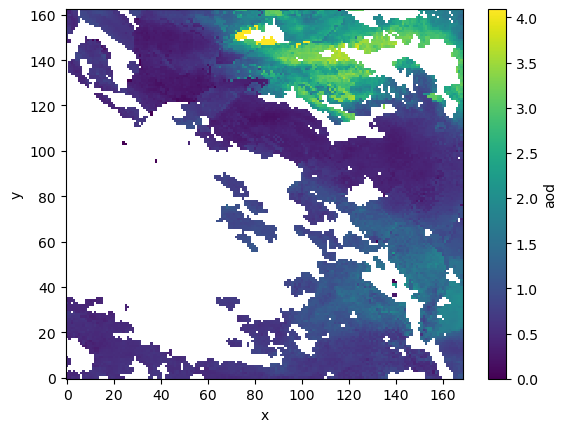

In [128]:
ds.aod.plot()